# 00 · Setup and inventory

Every notebook in this folder reads a release folder, read only, through `open_altio.faers.insights.source.connect()`: set `OPEN_ALTIO_RELEASE` to it, or `RELEASE` in the notebook's first code cell. No release yet? Build one with `open-altio demo` (FDA's latest quarter) or `open-altio build` (every quarter FDA published).

**Naming rule.** Raw FDA values are never modified. Objects holding only raw values keep plain names; anything derived (typed, parsed, deduplicated, filtered, reshaped) ends in `_T`, and so does every derived column. The raw column is always kept next to its `_T` version.

| object | grain | meaning |
|---|---|---|
| `demo_all`, `drug_all`, ... | every row FDA ever published | the release's raw tables (`demo`, `drug`, ...) under the names the notebooks use: every quarter, all versions, plus `quarter_T` / `era_T` provenance |
| `demo_T` | same rows as `demo_all` | adds typed columns: `caseversion_T`, `fda_dt_T`, `init_fda_dt_T`, `event_dt_T`, `first_fda_dt_T`, `init_year_T`, `fda_year_T`, `event_dt_prec_T`, `age_years_T`, `wt_kg_T`, `qnum_T` |
| `demo_latest_T` | one row per case | the latest version of each case, across AERS and FAERS |
| `deleted_cases_T` | caseid | union of the quarterly deleted-case lists (2019 Q1 onward) plus the all-history list |
| `case_latest_T` | one row per case | `demo_latest_T` minus the cases on FDA's deleted-case lists. **The analysis grain.** |
| `drug_latest_T`, `reac_latest_T`, ... | child rows of `case_latest_T` only | what you join for analysis |
| `quarters_T` | one row per published quarter | `qnum_T` sort key |

`era_T` is `legacy` (AERS, 2004 Q1 to 2012 Q3, ISR keys) or `faers` (2012 Q4 onward, primaryid / caseid / caseversion).

Every chart carries dotted guides at the known events (migration 2012Q4, schema change 2014Q3, e-sub mandate 2015Q3, COVID 2020Q1, and from 2025Q3 the rise of empty occupation codes shown in notebook 01), so a jump in a chart can be put down to its cause on sight.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from open_altio.faers.insights.cards.notebook import (
    SERIES,
    header,
    heatmap,
    mark_quarters,
    quarter_ticks,
    setup,
    title,
)
from open_altio.faers.insights.source import connect

setup()
# The release folder this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
con = connect(RELEASE)  # read only; raw tables as demo_all, drug_all, ... and the derived _T tables


def q(sql):
    return con.execute(sql).fetchdf()


q("select table_name, table_type from information_schema.tables order by table_type, table_name")

,table_name,table_type
0,input_lines_T,LOCAL TEMPORARY
1,atc_drug_T,VIEW
2,atc_drug_codes_T,VIEW
3,atc_index_T,VIEW
4,case_dedup_T,VIEW
5,case_dup_T,VIEW
6,case_latest_T,VIEW
7,deleted,VIEW
8,deleted_all,VIEW
9,deleted_cases_T,VIEW


## Inventory: rows per table per quarter

First sanity check. Gaps, dips or spikes here are almost always a publishing artifact (a re-issued quarter, a schema change) rather than a real-world event. One panel per table so each table's own scale is visible.

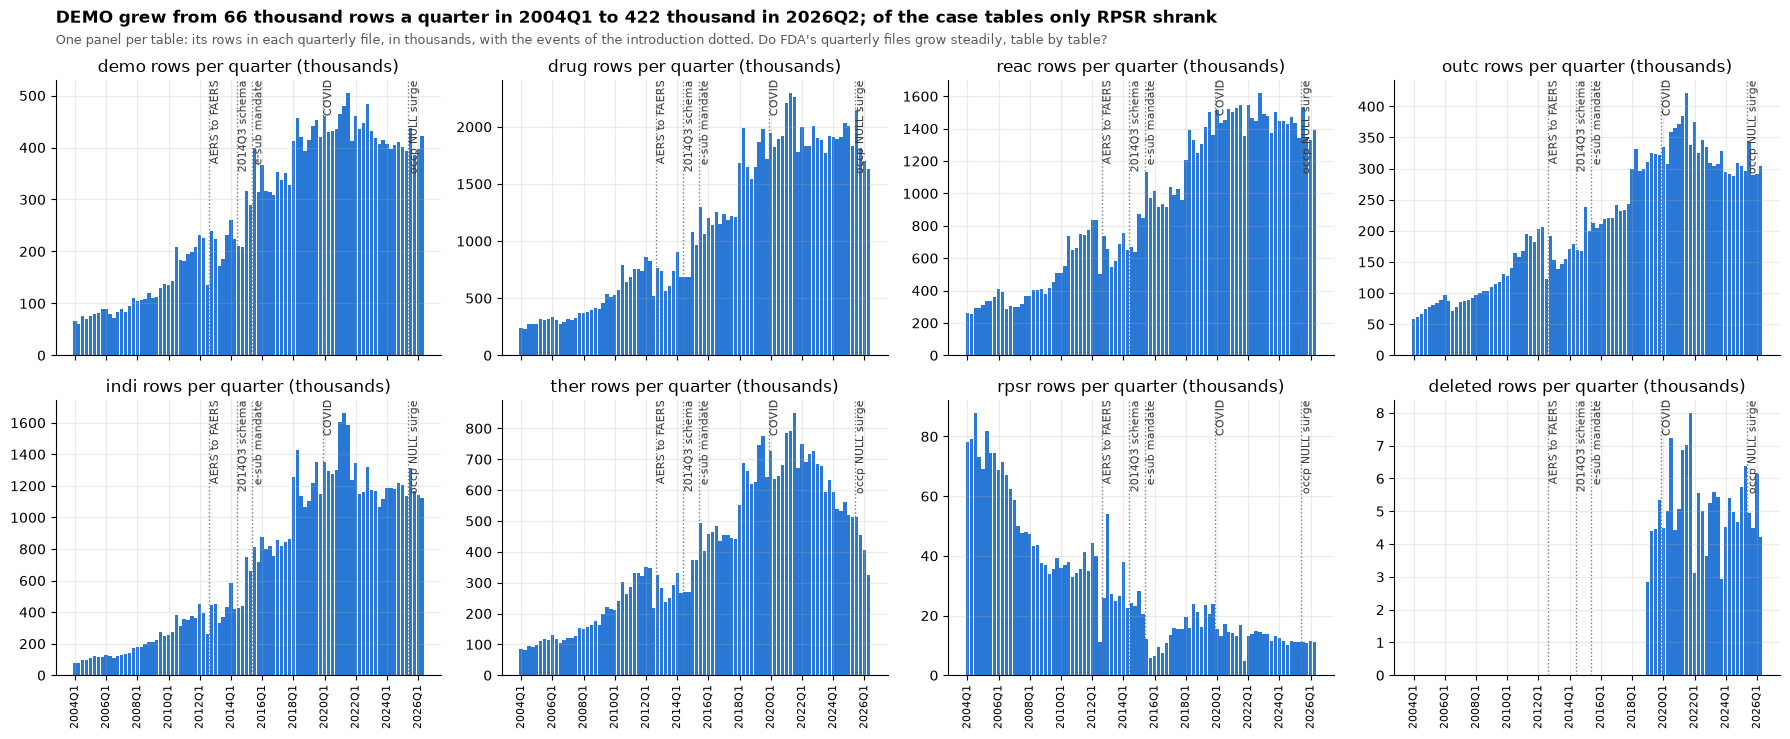

In [2]:
inv = q("""
with u as (
  select 'demo' t, quarter_T, era_T, count(*) n from demo_all group by all union all
  select 'drug', quarter_T, era_T, count(*) from drug_all group by all union all
  select 'reac', quarter_T, era_T, count(*) from reac_all group by all union all
  select 'outc', quarter_T, era_T, count(*) from outc_all group by all union all
  select 'rpsr', quarter_T, era_T, count(*) from rpsr_all group by all union all
  select 'ther', quarter_T, era_T, count(*) from ther_all group by all union all
  select 'indi', quarter_T, era_T, count(*) from indi_all group by all union all
  select 'deleted', quarter_T, 'faers', count(*) from deleted_all where quarter_T not like 'pre%' group by all)
pivot u on t using sum(n) group by quarter_T, era_T order by quarter_T""")
tables = ["demo", "drug", "reac", "outc", "indi", "ther", "rpsr", "deleted"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True)
for ax, t in zip(axes.flat, tables, strict=True):
    ax.bar(range(len(inv)), inv[t].fillna(0) / 1e3, width=0.85, color=SERIES[0])
    ax.set_title(f"{t} rows per quarter (thousands)")
    quarter_ticks(ax, inv.quarter_T, every=8)
    mark_quarters(ax, inv.quarter_T)
plt.tight_layout()
first, last = inv.iloc[0], inv.iloc[-1]
shrank = [t.upper() for t in tables if t != "deleted" and last[t] < first[t]]
title(
    header(fig),
    f"DEMO grew from {first.demo / 1e3:,.0f} thousand rows a quarter in {first.quarter_T.upper()} to "
    f"{last.demo / 1e3:,.0f} thousand in {last.quarter_T.upper()}; of the case tables only "
    f"{' and '.join(shrank) or 'none'} shrank",
    "One panel per table: its rows in each quarterly file, in thousands, with the events of the "
    "introduction dotted.",
    "Do FDA's quarterly files grow steadily, table by table?",
)
plt.show()

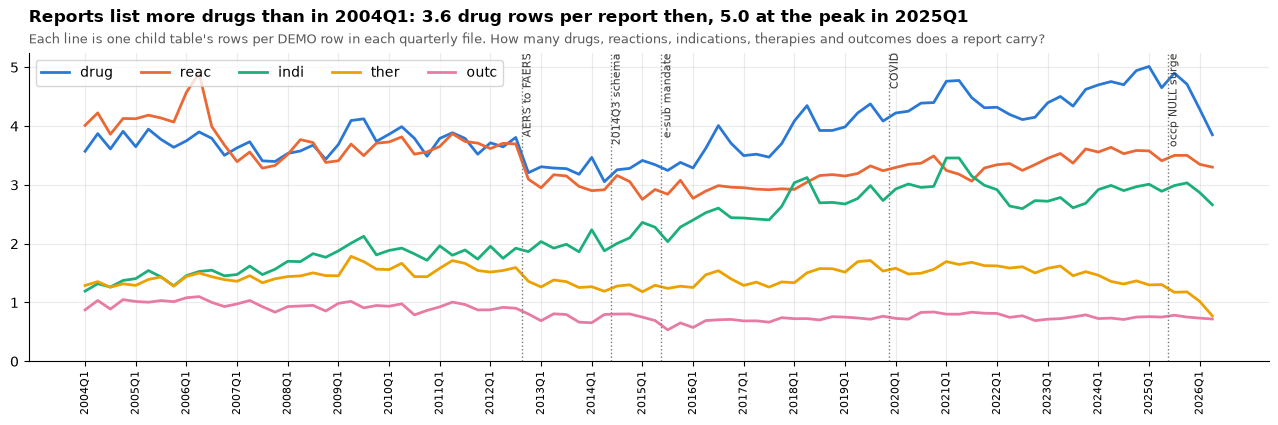

,quarter_T,era_T,deleted,demo,drug,indi,outc,reac,rpsr,ther
0,2004q1,legacy,NaN,65902.0,235361.0,78639.0,57592.0,264410.0,78306.0,84964.0
1,2004q2,legacy,NaN,60162.0,232925.0,79346.0,62217.0,254101.0,79231.0,81508.0
2,2004q3,legacy,NaN,75321.0,271996.0,95140.0,66868.0,290812.0,87737.0,94841.0
3,2004q4,legacy,NaN,70632.0,276197.0,97074.0,74040.0,291641.0,73001.0,93008.0
4,2005q1,legacy,NaN,75918.0,277055.0,106726.0,77193.0,313159.0,69159.0,97988.0
5,2005q2,legacy,NaN,80524.0,317883.0,124249.0,80866.0,337031.0,81944.0,112041.0
6,2005q3,legacy,NaN,81188.0,306277.0,116497.0,83824.0,335886.0,74416.0,116424.0
7,2005q4,legacy,NaN,88342.0,321483.0,113407.0,89580.0,359401.0,74459.0,112825.0
8,2006q1,legacy,NaN,89343.0,334994.0,130111.0,96515.0,408690.0,68831.0,128926.0
9,2006q2,legacy,NaN,79449.0,309882.0,121313.0,87399.0,389166.0,71326.0,119161.0


In [3]:
# rows per case: how the child tables grow relative to demo. A step here is a data-entry or schema change, not more patients.
r = inv.set_index("quarter_T")
fig, ax = plt.subplots(figsize=(16, 4))
for i, t in enumerate(["drug", "reac", "indi", "ther", "outc"]):
    ax.plot(range(len(r)), r[t] / r["demo"], label=t, color=SERIES[i])
peak = (r["drug"] / r["demo"]).idxmax()
title(
    ax,
    f"Reports list more drugs than in {r.index[0].upper()}: {r.drug.iloc[0] / r.demo.iloc[0]:.1f} drug "
    f"rows per report then, {r.drug[peak] / r.demo[peak]:.1f} at the peak in {peak.upper()}",
    "Each line is one child table's rows per DEMO row in each quarterly file.",
    "How many drugs, reactions, indications, therapies and outcomes does a report carry?",
)
ax.set_ylim(0)
quarter_ticks(ax, r.index)
mark_quarters(ax, r.index)
ax.legend(ncol=5, loc="upper left")
plt.show()
inv

## Load quality: rejected lines and values past the header

The release's `manifest.json` records, for every FDA file read, how many lines DuckDB could not parse and how many values sat past the header's last column. Rejected lines should be none. Values past the header are the long lines `rules/overlong-lines.md` records instead of dropping: FDA's 2012Q1 DEMO file holds one.

In [4]:
from open_altio.faers import read_manifest
from open_altio.faers.insights.source import release_folder

# every FDA file the release read
log = pd.DataFrame(read_manifest(release_folder(RELEASE))["inputs"])
print(
    "files read:",
    len(log),
    " total rejected lines:",
    int(log.rejected_lines.sum()),
    " values past the header:",
    int(log.overflow_values.sum()),
)
bad = log[(log.rejected_lines > 0) | (log.overflow_values > 0)]
if len(bad):
    display(bad)
else:
    print("no rejected lines and no values past the header")

files read: 661  total rejected lines: 0  values past the header: 1


,table,quarter,source,sha256,bytes,encoding,rows,rejected_lines,era,overflow_values,renamed,overlong_lines
224,demo,2012q1,aers_ascii_2012q1.zip/ascii/DEMO12Q1.TXT,64944a91c50b704b692ec7a9941631f542fbf7fe657b79...,32596710,utf-8,231737,0,legacy,1,"{'ISR': 'primaryid', 'CASE': 'caseid', 'I_F_CO...","[{'line': 105917, 'fields': 25, 'records': 1, ..."


## Versions, cases, deletions

How much of the raw row count is follow-up versions of the same case, how many cases FDA later nullified, and how many of those nullified caseids ever appeared in a published file. A primaryid (or legacy ISR) can also be published in more than one quarter; those re-issues are counted here.

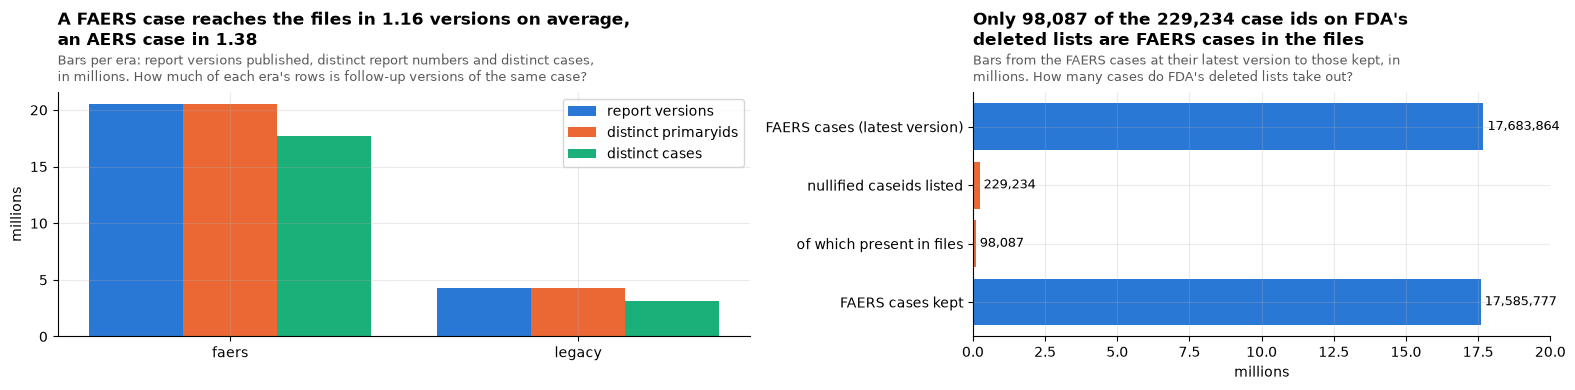

,era_T,report_versions,distinct_primaryids,distinct_cases,reissued_rows,versions_per_case
0,faers,20536224,20535517,17683864,707,1.161
1,legacy,4276201,4271507,3091161,4694,1.383


In [5]:
v = q("""
select era_T,
  count(*)                          as report_versions,
  count(distinct primaryid)         as distinct_primaryids,
  count(distinct caseid)            as distinct_cases,
  count(*) - count(distinct primaryid) as reissued_rows,
  round(count(*)*1.0/count(distinct caseid),3) as versions_per_case
from demo_all group by 1 order by 1""")
d = q("""
select
  (select count(*) from demo_latest_T where era_T='faers')   as faers_cases_latest_version,
  (select count(*) from deleted_cases_T)                     as nullified_caseids_listed,
  (select count(*) from deleted_cases_T d where exists (select 1 from demo_latest_T m where m.era_T='faers' and m.caseid=d.caseid)) as nullified_present_in_files,
  (select count(*) from case_latest_T  where era_T='faers')  as faers_cases_after_removing_nullified,
  (select count(*) from case_latest_T  where era_T='legacy') as legacy_cases""").iloc[0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [1.2, 1]})
x = np.arange(2)
w = 0.27
for i, col in enumerate(["report_versions", "distinct_primaryids", "distinct_cases"]):
    a1.bar(x + (i - 1) * w, v[col] / 1e6, w, label=col.replace("_", " "), color=SERIES[i])
a1.set_xticks(x)
a1.set_xticklabels(v.era_T)
a1.set_ylabel("millions")
per = v.set_index("era_T").versions_per_case
title(
    a1,
    f"A FAERS case reaches the files in {per.faers:.2f} versions on average, an AERS case in "
    f"{per.legacy:.2f}",
    "Bars per era: report versions published, distinct report numbers and distinct cases, in millions.",
    "How much of each era's rows is follow-up versions of the same case?",
)
a1.legend()
steps = [
    "FAERS cases (latest version)",
    "nullified caseids listed",
    "of which present in files",
    "FAERS cases kept",
]
vals = [
    d.faers_cases_latest_version,
    d.nullified_caseids_listed,
    d.nullified_present_in_files,
    d.faers_cases_after_removing_nullified,
]
a2.barh(steps[::-1], np.array(vals[::-1]) / 1e6, color=[SERIES[0], SERIES[1], SERIES[1], SERIES[0]])
for y, val in zip(range(4), vals[::-1], strict=True):
    a2.text(val / 1e6, y, f" {val:,}", va="center", fontsize=9)
a2.set_xlabel("millions")
title(
    a2,
    f"Only {d.nullified_present_in_files:,} of the {d.nullified_caseids_listed:,} case ids on FDA's "
    "deleted lists are FAERS cases in the files",
    "Bars from the FAERS cases at their latest version to those kept, in millions.",
    "How many cases do FDA's deleted lists take out?",
)
a2.set_xlim(0, 20)
plt.tight_layout()
plt.show()
v

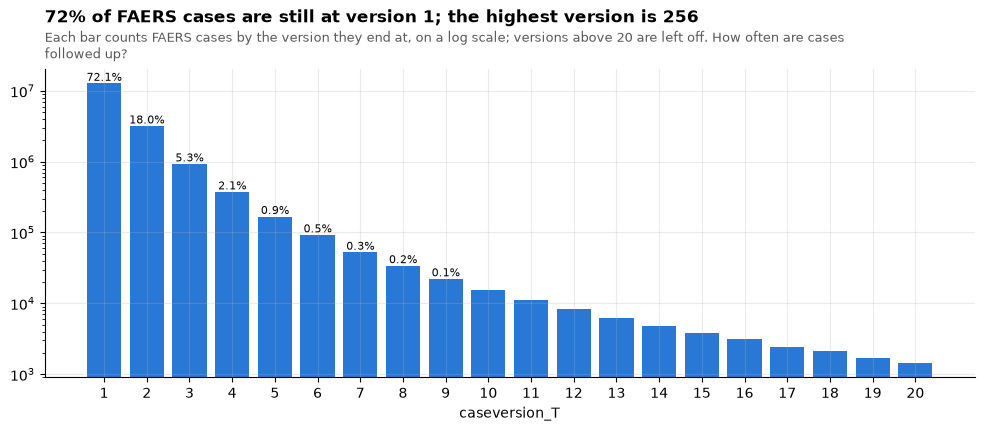

,caseversion_T,n,pct
0,1,12681733,72.11
1,2,3168882,18.02
2,3,924667,5.26
3,4,372097,2.12
4,5,167400,0.95
5,6,92172,0.52
6,7,52290,0.30
7,8,33823,0.19
8,9,22080,0.13
9,10,15330,0.09


In [6]:
# distribution of caseversion at latest state: how many cases get followed up, and how often
cv = q("""
select caseversion_T, count(*) n, round(100.0*count(*)/sum(count(*)) over (),2) as pct
from case_latest_T where era_T='faers' group by 1 order by 1""")
fig, ax = plt.subplots(figsize=(12, 4))
top = cv[cv.caseversion_T <= 20]
ax.bar(top.caseversion_T, top.n, color=SERIES[0])
ax.set_yscale("log")
ax.set_xticks(top.caseversion_T)
for xx, n, p in zip(top.caseversion_T, top.n, top.pct, strict=True):
    if p >= 0.1:
        ax.text(xx, n, f"{p:.1f}%", ha="center", va="bottom", fontsize=8)
title(
    ax,
    f"{cv.pct.iloc[0]:.0f}% of FAERS cases are still at version {int(cv.caseversion_T.iloc[0])}; the "
    f"highest version is {int(cv.caseversion_T.max())}",
    "Each bar counts FAERS cases by the version they end at, on a log scale; versions above 20 are "
    "left off.",
    "How often are cases followed up?",
)
ax.set_xlabel("caseversion_T")
plt.show()
cv.head(15)

## Schema eras in the data

Which fields are populated from when. A field that is NULL for an entire era is a schema boundary, not missing data. Each cell is the % of rows in that quarter with a non-null value.

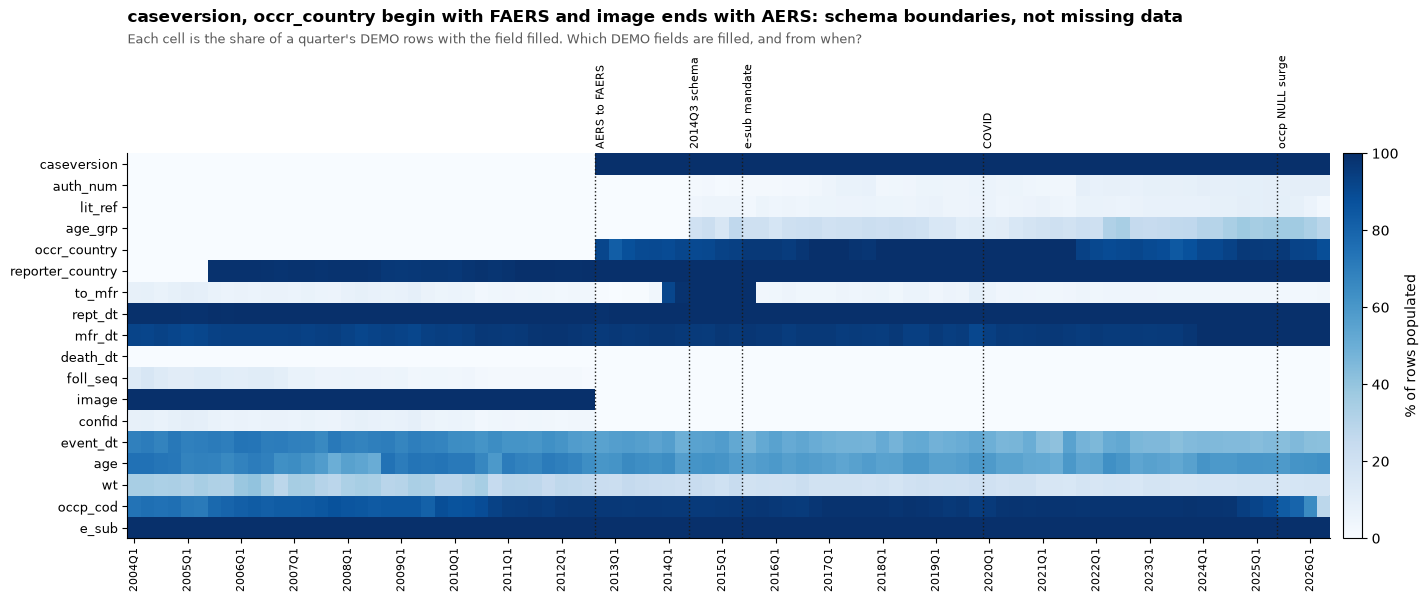

,quarter_T,era_T,n,caseversion,auth_num,lit_ref,age_grp,occr_country,reporter_country,to_mfr,rept_dt,mfr_dt,death_dt,foll_seq,image,confid,event_dt,age,wt,occp_cod,e_sub
0,2004q1,legacy,65902,0.0,0.0,0.0,0.0,0.0,0.0,7.9,99.4,92.0,0.0,13.2,100.0,7.9,68.8,74.9,34.3,73.9,100.0
1,2004q2,legacy,60162,0.0,0.0,0.0,0.0,0.0,0.0,8.5,99.5,91.5,0.0,15.8,100.0,8.5,70.4,74.7,34.0,75.4,100.0
2,2004q3,legacy,75321,0.0,0.0,0.0,0.0,0.0,0.0,7.0,99.6,92.9,0.0,12.5,100.0,7.0,67.7,73.1,33.2,74.8,100.0
3,2004q4,legacy,70632,0.0,0.0,0.0,0.0,0.0,0.0,8.3,99.4,91.7,0.0,11.0,100.0,8.3,72.0,72.6,33.3,75.5,100.0
4,2005q1,legacy,75918,0.0,0.0,0.0,0.0,0.0,0.0,9.4,99.2,90.6,0.0,11.3,100.0,9.4,69.0,67.7,31.8,71.9,100.0
5,2005q2,legacy,80524,0.0,0.0,0.0,0.0,0.0,0.0,8.8,99.1,91.2,0.0,12.2,100.0,8.8,69.8,68.4,34.1,71.1,100.0
6,2005q3,legacy,81188,0.0,0.0,0.0,0.0,0.0,99.0,7.0,99.7,93.0,0.0,12.3,100.0,7.0,70.8,68.3,32.4,77.8,100.0
7,2005q4,legacy,88342,0.0,0.0,0.0,0.0,0.0,99.0,6.2,99.6,93.7,0.0,10.9,100.0,6.2,69.6,65.8,31.7,79.8,100.0
8,2006q1,legacy,89343,0.0,0.0,0.0,0.0,0.0,99.2,6.6,99.7,93.4,0.0,10.2,100.0,6.6,73.8,68.2,38.4,81.8,100.0
9,2006q2,legacy,79449,0.0,0.0,0.0,0.0,0.0,99.1,6.2,99.8,93.7,0.0,11.4,100.0,6.2,73.4,70.6,40.4,83.1,100.0


In [7]:
cols = [
    "caseversion",
    "auth_num",
    "lit_ref",
    "age_grp",
    "occr_country",
    "reporter_country",
    "to_mfr",
    "rept_dt",
    "mfr_dt",
    "death_dt",
    "foll_seq",
    "image",
    "confid",
    "event_dt",
    "age",
    "wt",
    "occp_cod",
    "e_sub",
]
expr = ", ".join(f"round(100.0*count({c})/count(*),1) as {c}" for c in cols)
pop = q(f"select quarter_T, era_T, count(*) n, {expr} from demo_all group by 1,2 order by 1")
by_era = pop.groupby("era_T")[cols].mean()
began = [c for c in cols if by_era.loc["legacy", c] < 1 and by_era.loc["faers", c] > 50]
ended = [c for c in cols if by_era.loc["legacy", c] > 50 and by_era.loc["faers", c] < 1]
heatmap(
    pop.set_index("quarter_T")[cols].T,
    f"{', '.join(began)} begin with FAERS and {', '.join(ended)} ends with AERS: schema "
    "boundaries, not missing data",
    "Each cell is the share of a quarter's DEMO rows with the field filled.",
    "Which DEMO fields are filled, and from when?",
)
pop

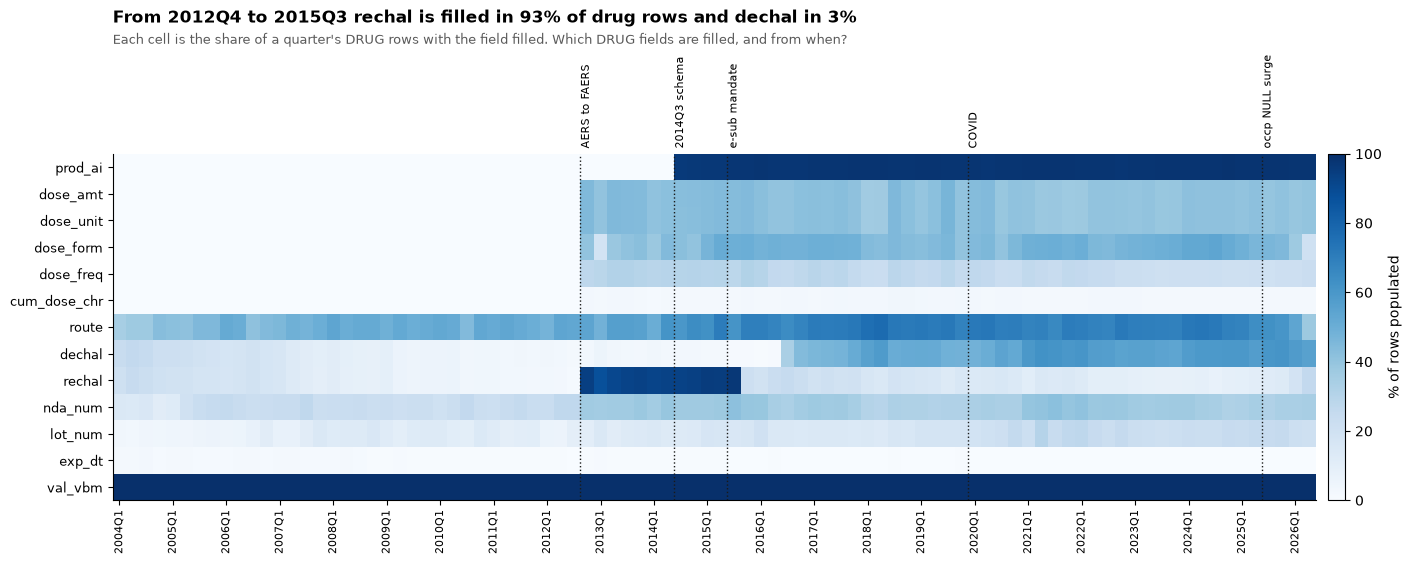

,quarter_T,era_T,n,prod_ai,dose_amt,dose_unit,dose_form,dose_freq,cum_dose_chr,route,dechal,rechal,nda_num,lot_num,exp_dt,val_vbm
0,2004q1,legacy,235361,0.0,0.0,0.0,0.0,0.0,0.0,34.5,23.7,20.9,14.1,3.2,1.9,100.0
1,2004q2,legacy,232925,0.0,0.0,0.0,0.0,0.0,0.0,37.4,25.9,24.6,14.0,2.8,1.7,100.0
2,2004q3,legacy,271996,0.0,0.0,0.0,0.0,0.0,0.0,37.3,24.8,22.1,15.1,4.2,2.4,100.0
3,2004q4,legacy,276197,0.0,0.0,0.0,0.0,0.0,0.0,43.0,21.3,20.0,11.1,3.8,1.5,100.0
4,2005q1,legacy,277055,0.0,0.0,0.0,0.0,0.0,0.0,41.9,21.2,18.9,12.4,4.6,1.8,100.0
5,2005q2,legacy,317883,0.0,0.0,0.0,0.0,0.0,0.0,41.3,20.9,19.2,19.8,4.2,1.6,100.0
6,2005q3,legacy,306277,0.0,0.0,0.0,0.0,0.0,0.0,45.3,19.0,17.9,23.1,4.7,1.5,100.0
7,2005q4,legacy,321483,0.0,0.0,0.0,0.0,0.0,0.0,45.0,18.2,17.3,24.8,5.7,1.3,100.0
8,2006q1,legacy,334994,0.0,0.0,0.0,0.0,0.0,0.0,51.8,16.9,16.6,25.5,4.9,1.3,100.0
9,2006q2,legacy,309882,0.0,0.0,0.0,0.0,0.0,0.0,50.2,17.7,17.4,24.2,5.4,1.9,100.0


In [8]:
cols = [
    "prod_ai",
    "dose_amt",
    "dose_unit",
    "dose_form",
    "dose_freq",
    "cum_dose_chr",
    "route",
    "dechal",
    "rechal",
    "nda_num",
    "lot_num",
    "exp_dt",
    "val_vbm",
]
expr = ", ".join(f"round(100.0*count({c})/count(*),1) as {c}" for c in cols)
dpop = q(f"select quarter_T, era_T, count(*) n, {expr} from drug_all group by 1,2 order by 1")
swap = dpop[dpop.quarter_T.between("2012q4", "2015q3")]
heatmap(
    dpop.set_index("quarter_T")[cols].T,
    f"From 2012Q4 to 2015Q3 rechal is filled in {swap.rechal.mean():.0f}% of drug rows and dechal "
    f"in {swap.dechal.mean():.0f}%",
    "Each cell is the share of a quarter's DRUG rows with the field filled.",
    "Which DRUG fields are filled, and from when?",
    figsize=(16, 4.5),
)
dpop

The DRUG map shows the dechal / rechal regime change: 2012Q4 to 2015Q3 `rechal` is filled for over 90% of rows while `dechal` is near empty, 2015Q4 to 2016Q2 both are near empty, and `dechal` only becomes populated from 2016Q3. Legacy populated both at similar, declining rates. The release keeps both fields as FDA wrote them; the D that fills `rechal` 2012Q4 to 2015Q3 is a filler, not an answer (the `rechal_filler` card below), and `dechal` stays near empty to 2016Q2, so any rechallenge or dechallenge analysis has to read the three periods together.

## Typed columns: how much survives the parse

For each `_T` column, the share of raw values that parse. A raw value that does not parse is kept as-is in the raw column; this just says how much of the analysis will run on the typed column.

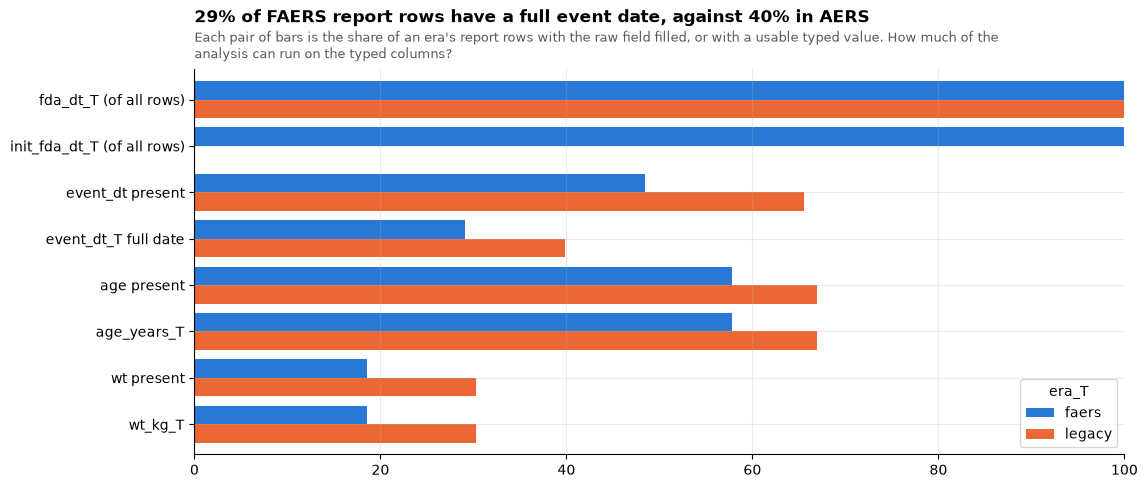

era_T,faers,legacy
fda_dt_T (of all rows),100.0,100.0
init_fda_dt_T (of all rows),100.0,0.0
event_dt present,48.5,65.6
event_dt_T full date,29.1,39.8
age present,57.8,66.9
age_years_T,57.8,66.9
wt present,18.6,30.3
wt_kg_T,18.6,30.3


In [9]:
pr = (
    q("""
select era_T,
  round(100.0*count(fda_dt_T)/count(*),1)            as "fda_dt_T (of all rows)",
  round(100.0*count(init_fda_dt_T)/count(*),1)       as "init_fda_dt_T (of all rows)",
  round(100.0*count(event_dt)/count(*),1)            as "event_dt present",
  round(100.0*count(event_dt_T)/count(*),1)          as "event_dt_T full date",
  round(100.0*count(age)/count(*),1)                 as "age present",
  round(100.0*count(age_years_T)/count(*),1)         as "age_years_T",
  round(100.0*count(wt)/count(*),1)                  as "wt present",
  round(100.0*count(wt_kg_T)/count(*),1)             as "wt_kg_T"
from demo_T group by 1 order by 1""")
    .set_index("era_T")
    .T
)
ax = pr.plot(kind="barh", figsize=(12, 5), color=[SERIES[0], SERIES[1]], width=0.8)
full = pr.loc["event_dt_T full date"]
title(
    ax,
    f"{full.faers:.0f}% of FAERS report rows have a full event date, against {full.legacy:.0f}% "
    "in AERS",
    "Each pair of bars is the share of an era's report rows with the raw field filled, or with a "
    "usable typed value.",
    "How much of the analysis can run on the typed columns?",
)
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(title="era_T")
plt.show()
pr

## Methods-page cards from this notebook

The cards below are computed by the same functions the release build calls (`src/open_altio/faers/insights/cards`), so the chart data on the methods page is reproducible from this code. Each card is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT`) for checking; the release carries them in `methods.json`.

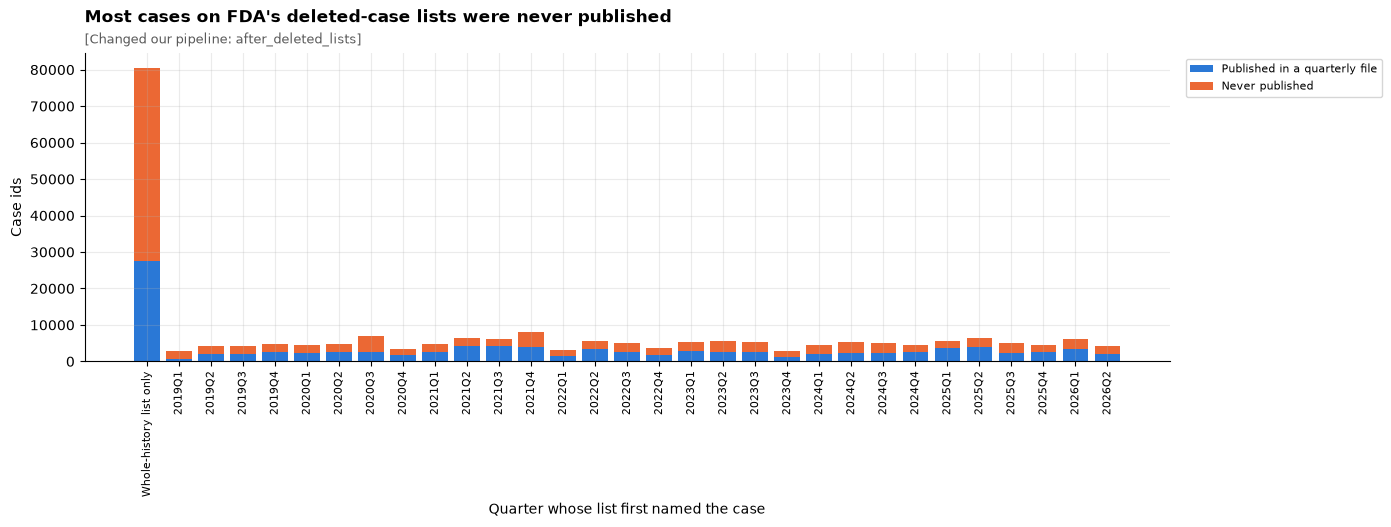

FDA's deleted-case lists name 229,234 case ids, but only 104,161 of them (45%) ever appeared in a published quarterly file. We remove every published one from the release; the others never reached the files, so there is nothing to remove.


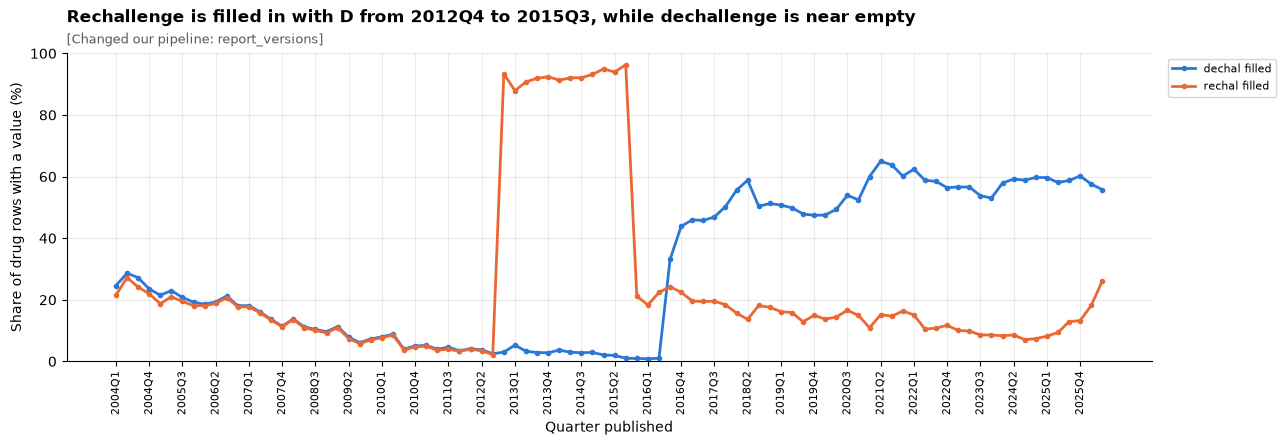

From 2012Q4 to 2015Q3 the rechallenge field is filled for over 90% of drug rows, mostly with D, does not apply, while dechallenge is almost empty until 2016Q3. When the same drug comes back in a later version, almost every D is gone, so the D is a filler, not an answer swapped with dechallenge.
notebooks/out/cards/00_setup_and_inventory.json


In [10]:
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import plot_card, write_cards

cards = compute_cards(con, ["deleted_lists_unpublished", "rechal_filler"])
for card in cards:
    plot_card(card)
print(write_cards(cards, "00_setup_and_inventory"))